### Setup

Setup imports and load dataset

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import(accuracy_score, f1_score, roc_auc_score, average_precision_score, RocCurveDisplay)

SEED = 42

PROJECT_ROOT = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())

DATA_DIR = PROJECT_ROOT / "data" / "processed"

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")

print("Training: ", train_df.shape)
print("Validation: ", val_df.shape)

Training:  (17716, 3)
Validation:  (3127, 3)


### 1. Statistical Baseline

In [2]:
# Baseline training
X_train = train_df[["gc_content"]]
y_train = train_df["label"]

X_val = val_df[["gc_content"]]
y_val = val_df["label"]

gc_model = LogisticRegression(random_state=SEED)

gc_model.fit(X_train, y_train)

predictions = gc_model.predict(X_val)

probabilities = gc_model.predict_proba(X_val)[:, 1]

In [3]:
# Baseline evaluation
gc_metrics = {
    "model": "GC Logistic Regression",
    "accuracy": accuracy_score(y_val, predictions),
    "f1": f1_score(y_val, predictions),
    "auroc": roc_auc_score(y_val, probabilities),
    "auprc_ap": average_precision_score(y_val, probabilities)
}

display(pd.DataFrame([gc_metrics]))

,model,accuracy,f1,auroc,auprc_ap
0,GC Logistic Regression,0.669332,0.654181,0.732831,0.74179


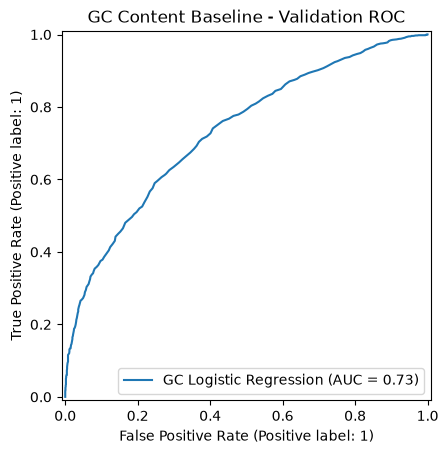

In [4]:
# Visualization of baseline model performance
RocCurveDisplay.from_predictions(y_val, probabilities, name="GC Logistic Regression")

plt.title("GC Content Baseline - Validation ROC")
plt.show()

In [5]:
# Save Results
RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame([gc_metrics]).to_csv(RESULTS_DIR / "gc_baseline.csv", index=False)